In [1]:
pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
student_performance = fetch_ucirepo(id=320)

# data (as pandas dataframes)
X = student_performance.data.features
y = student_performance.data.targets

# metadata
print(student_performance.metadata)

# variable information
print(student_performance.variables)


{'uci_id': 320, 'name': 'Student Performance', 'repository_url': 'https://archive.ics.uci.edu/dataset/320/student+performance', 'data_url': 'https://archive.ics.uci.edu/static/public/320/data.csv', 'abstract': 'Predict student performance in secondary education (high school). ', 'area': 'Social Science', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 649, 'num_features': 30, 'feature_types': ['Integer'], 'demographics': ['Sex', 'Age', 'Other', 'Education Level', 'Occupation'], 'target_col': ['G1', 'G2', 'G3'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Fri Jan 05 2024', 'dataset_doi': '10.24432/C5TG7T', 'creators': ['Paulo Cortez'], 'intro_paper': {'ID': 360, 'type': 'NATIVE', 'title': 'Using data mining to predict secondary school student performance', 'authors': 'P. Cortez, A. M. G. Silva', 'venue': 'Proceedings of 5th Annual Future Business Technolo

(395, 33)
G3
1    265
0    130
Name: count, dtype: int64
(316, 30) (79, 30)
G3
1    53
0    26
Name: count, dtype: int64
Melhores parâmetros: {'knn__metric': 'euclidean', 'knn__n_neighbors': 2, 'knn__weights': 'uniform'}
F1 (reprovado) na validação cruzada: 0.4293


,Modelo,Acurácia,Revocação,F1-score
0,Dummy Classifier,0.6709,0.0000,0.0000
1,KNN,0.5443,0.7692,0.5263


              precision    recall  f1-score   support

   Reprovado       0.40      0.77      0.53        26
    Aprovado       0.79      0.43      0.56        53

    accuracy                           0.54        79
   macro avg       0.60      0.60      0.54        79
weighted avg       0.66      0.54      0.55        79



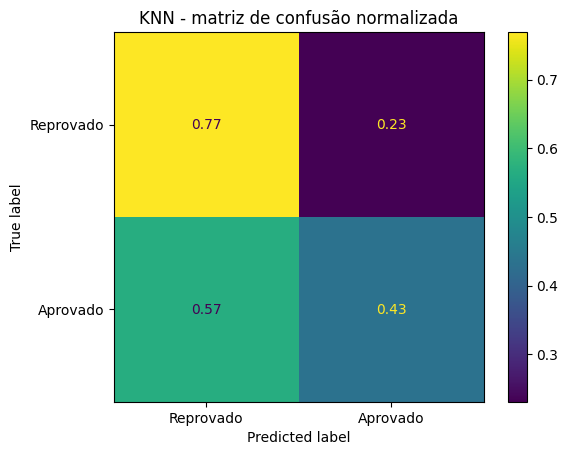

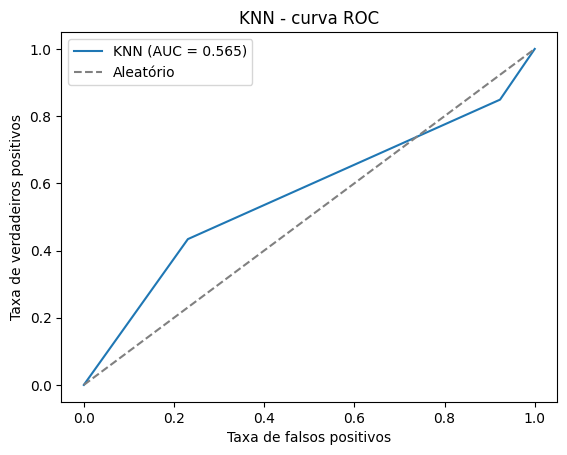

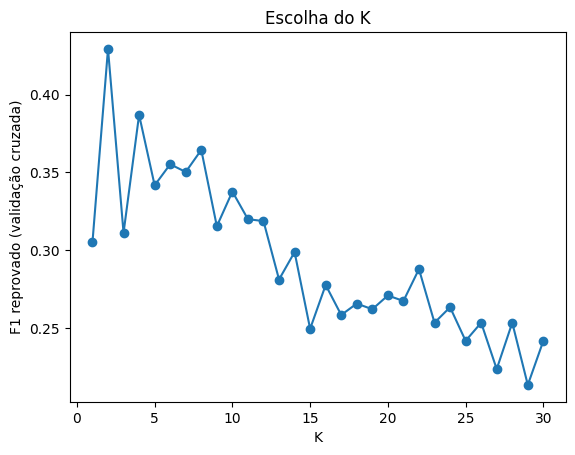

,Modelo,Acurácia,Revocação,F1-score,AUC
0,Dummy Classifier,0.6709,0.0000,0.0000,0.5000
1,Decision Tree,0.6709,0.5769,0.5357,0.6470
2,KNN,0.5443,0.7692,0.5263,0.5653


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [5]:
# ============================================================
# KNN - Student Performance (student-mat.csv)
# Mesmo problema da Árvore de Decisão do seu amigo
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, make_scorer,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42  # TROQUE pelo valor que seu amigo usou

# ------------------------------------------------------------
# 1. Dados e alvo (1 = aprovado, 0 = reprovado)
# ------------------------------------------------------------
df = pd.read_csv("student-mat.csv", sep=";")
y = (df["G3"] >= 10).astype(int)
X = df.drop(columns=["G1", "G2", "G3"])

print(df.shape)
print(y.value_counts())          # 265 aprovados e 130 reprovados

# ------------------------------------------------------------
# 2. Divisão treino/teste (80/20 estratificada)
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)   # (316, 30) e (79, 30)
print(y_test.value_counts())         # 53 aprovados e 26 reprovados

# ------------------------------------------------------------
# 3. Pipeline: one-hot + padronização + KNN
# ------------------------------------------------------------
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

pipe = Pipeline([
    ("prep", preprocess),
    ("knn", KNeighborsClassifier()),
])

# ------------------------------------------------------------
# 4. GridSearchCV (5 folds estratificados, F1 da classe Reprovado)
# ------------------------------------------------------------
f1_reprovado = make_scorer(f1_score, pos_label=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "knn__n_neighbors": range(1, 31),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring=f1_reprovado, n_jobs=-1)
grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print("F1 (reprovado) na validação cruzada:", round(grid.best_score_, 4))

# ------------------------------------------------------------
# 5. Avaliação no teste: Dummy vs KNN (mesmo formato do seu amigo)
# ------------------------------------------------------------
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

previsao_dummy = dummy.predict(X_test)
previsao_knn = grid.predict(X_test)

resultados = pd.DataFrame({
    "Modelo": ["Dummy Classifier", "KNN"],
    "Acurácia": [
        accuracy_score(y_test, previsao_dummy),
        accuracy_score(y_test, previsao_knn),
    ],
    "Revocação": [
        recall_score(y_test, previsao_dummy, pos_label=0, zero_division=0),
        recall_score(y_test, previsao_knn, pos_label=0),
    ],
    "F1-score": [
        f1_score(y_test, previsao_dummy, pos_label=0, zero_division=0),
        f1_score(y_test, previsao_knn, pos_label=0),
    ],
})
display(resultados.round(4))

print(classification_report(y_test, previsao_knn,
                            target_names=["Reprovado", "Aprovado"]))

# ------------------------------------------------------------
# 6. Matriz de confusão normalizada por linha
# ------------------------------------------------------------
ConfusionMatrixDisplay.from_predictions(
    y_test, previsao_knn, normalize="true",
    display_labels=["Reprovado", "Aprovado"]
)
plt.title("KNN - matriz de confusão normalizada")
plt.show()

# ------------------------------------------------------------
# 7. Curva ROC e AUC
# ------------------------------------------------------------
proba = grid.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

plt.plot(fpr, tpr, label=f"KNN (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("KNN - curva ROC")
plt.legend()
plt.show()

# ------------------------------------------------------------
# 8. K vs. desempenho na validação cruzada (para o relatório)
# ------------------------------------------------------------
res = pd.DataFrame(grid.cv_results_)
res = res[(res["param_knn__weights"] == grid.best_params_["knn__weights"]) &
          (res["param_knn__metric"] == grid.best_params_["knn__metric"])]

plt.plot(res["param_knn__n_neighbors"], res["mean_test_score"], marker="o")
plt.xlabel("K")
plt.ylabel("F1 reprovado (validação cruzada)")
plt.title("Escolha do K")
plt.show()

# ------------------------------------------------------------
# 9. Comparação final com a Árvore de Decisão (valores dos slides dele)
# ------------------------------------------------------------
final = pd.DataFrame({
    "Modelo": ["Dummy Classifier", "Decision Tree", "KNN"],
    "Acurácia": [0.6709, 0.6709, accuracy_score(y_test, previsao_knn)],
    "Revocação": [0.0, 0.5769, recall_score(y_test, previsao_knn, pos_label=0)],
    "F1-score": [0.0, 0.5357, f1_score(y_test, previsao_knn, pos_label=0)],
    "AUC": [0.5, 0.647, auc],
})
display(final.round(4))

In [6]:
knn_padrao = Pipeline([
    ("prep", preprocess),
    ("knn", KNeighborsClassifier()),   # n_neighbors=5 por padrão
]).fit(X_train, y_train)

prev = knn_padrao.predict(X_test)
print("Acurácia: ", accuracy_score(y_test, prev))
print("Revocação:", recall_score(y_test, prev, pos_label=0))
print("F1-score: ", f1_score(y_test, prev, pos_label=0))

Acurácia:  0.5822784810126582
Revocação: 0.19230769230769232
F1-score:  0.23255813953488372
